# Importing libraries

In [128]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from openpyxl.utils.datetime import time_to_days

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA

import datetime as dt

# Loading data

In [129]:
df = pd.read_excel(r'/Users/rr8/Desktop/Retail Data Clustering Project/online_retail_II.xlsx', parse_dates=['InvoiceDate'])

# Data Preprocessing

In [130]:
df.shape

(525461, 8)

In [131]:
df.head(3)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom


In [132]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

In [133]:
df[['Invoice', 'StockCode', 'Description']] = df[['Invoice', 'StockCode', 'Description']].astype(str)

In [134]:
# Checking missing values
df.isna().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [135]:
df[['Quantity', 'Price']].describe()

,Quantity,Price
count,"525,461.00","525,461.00"
mean,10.34,4.69
std,107.42,146.13
min,"-9,600.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.21
max,"19,152.00","25,111.09"


In [136]:
# Checking description values and how many are the rows with negative 'Price'

df_test = df[df['Price'] < 0]

df_test_uniq_description = df_test['Description'].unique()
print(f'Unique values: {df_test_uniq_description}')
print(df_test['Description'].describe())

Unique values: <StringArray>
['Adjust bad debt']
Length: 1, dtype: str
count                   3
unique                  1
top       Adjust bad debt
freq                    3
Name: Description, dtype: object


In [137]:
# Excluding Bad Debt rows from the dataset

df = df[df['Description'] != 'Adjust bad debt']

Dataset variable context info: If 'Invoice' field value starts with Letter C - that indicates a Cancelled order

In [138]:
# Creating a flag column for Cancelled orders

df['Cancellation_flag'] = df['Invoice'].str.startswith('C').astype(int)

In [139]:
df[df['Cancellation_flag'] == 0].describe()

,Quantity,InvoiceDate,Price,Customer ID,Cancellation_flag
count,"515,252.00",515252,"515,252.00","407,695.00","515,252.00"
mean,10.96,2010-06-28 17:40:54.093764,4.22,"15,368.50",0.00
min,"-9,600.00",2009-12-01 07:45:00,0.00,"12,346.00",0.00
25%,1.00,2010-03-21 13:27:00,1.25,"13,997.00",0.00
50%,3.00,2010-07-06 13:13:00,2.10,"15,321.00",0.00
75%,10.00,2010-10-15 14:27:00,4.21,"16,812.00",0.00
max,"19,152.00",2010-12-09 20:01:00,"25,111.09","18,287.00",0.00
std,104.35,NaN,63.44,"1,679.80",0.00


In [140]:
# Not canceled orders, with <0 Quantity OR Price == 0
unknown_negative = df[ (df['Cancellation_flag'] == 0) &
                        (
                               (df['Quantity'] < 0) |
                               (df['Price'] == 0)
                        )
                    ]

# Dropping rows since its 0.007 % from df and hold no significant information
df = df.drop(unknown_negative.index).reset_index()

In [141]:
# Creating missing Customer ID flag as a new field that might come in handy later

df['MissingCustomer_flag'] = df['Customer ID'].isna().astype(int)

df['MissingCustomer_flag'].value_counts(normalize=True)

MissingCustomer_flag
0   0.80
1   0.20
Name: proportion, dtype: float64

In [142]:
# Updating the missing values for Customer ID, replacing the value with value 0

missing_customer = df['Customer ID'].isna()

df.loc[missing_customer, 'Customer ID'] = 0

In [143]:
df.isna().sum()

index                   0
Invoice                 0
StockCode               0
Description             0
Quantity                0
InvoiceDate             0
Price                   0
Customer ID             0
Country                 0
Cancellation_flag       0
MissingCustomer_flag    0
dtype: int64

In [144]:
# Creating Date and Year-Month columns

df['Date'] = df['InvoiceDate'].dt.strftime('%Y-%m-%d')
df['Year-Month'] = df['InvoiceDate'].dt.strftime('%Y-%m')

# Simple EDA

In [145]:
df[['Price', 'Quantity']].describe()

,Price,Quantity
count,"521,771.00","521,771.00"
mean,4.98,10.77
std,96.83,90.82
min,0.00,"-9,360.00"
25%,1.25,1.00
50%,2.10,3.00
75%,4.21,10.00
max,"25,111.09","19,152.00"


In [146]:
df_agg_price_volume = df.groupby(['Date', 'Cancellation_flag'])['Price'].sum().reset_index()
df_agg_quantity_volume = df.groupby(['Date', 'Cancellation_flag'])['Quantity'].sum().reset_index()

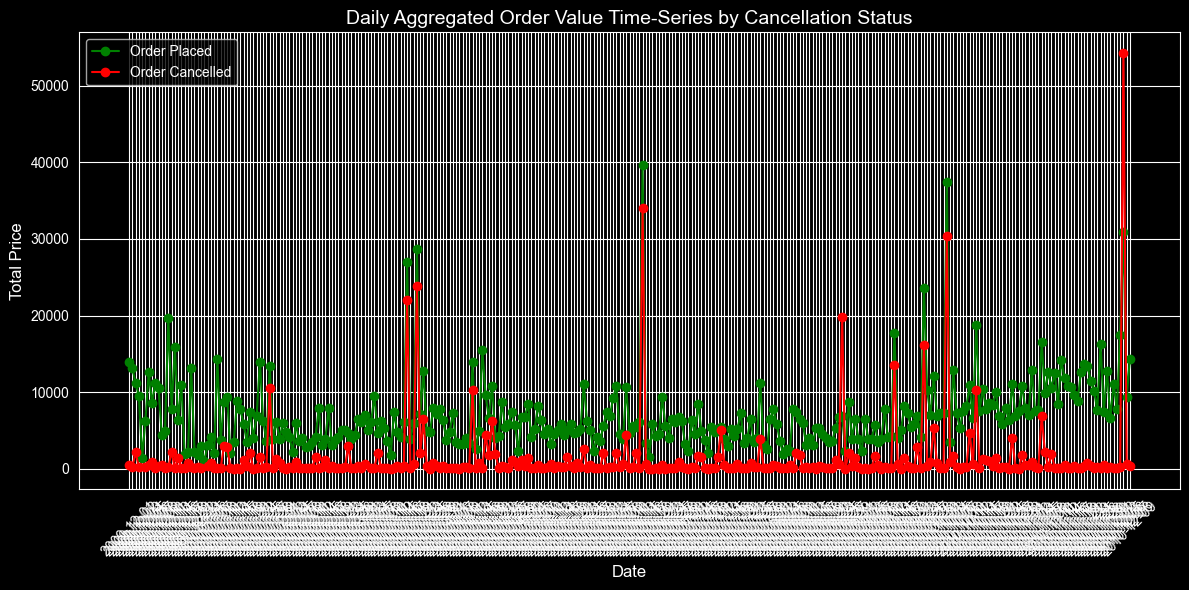

In [147]:
plt.figure(figsize=(12, 6))
for flag, color, label in [(0, 'g', 'Order Placed'), (1, 'r', 'Order Cancelled')]:
    data = df_agg_price_volume[df_agg_price_volume['Cancellation_flag'] == flag]
    plt.plot(data['Date'], data['Price'], marker='o', linestyle='-', color=color, label=label)

plt.title('Daily Aggregated Order Value Time-Series by Cancellation Status', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Price', fontsize=12)
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

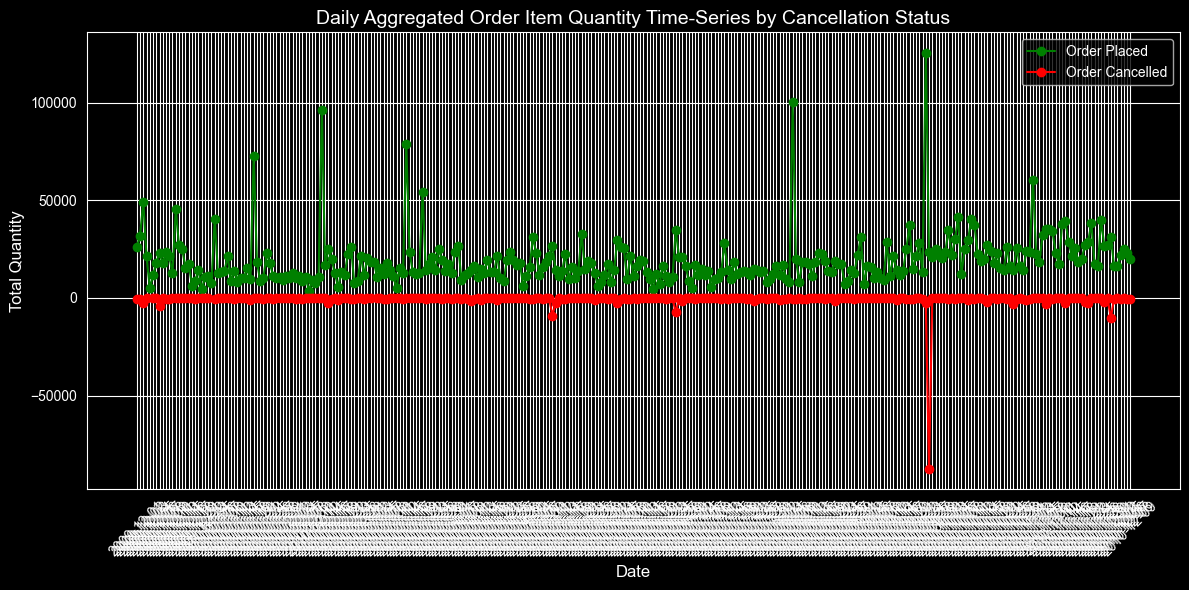

In [148]:
plt.figure(figsize=(12, 6))
for flag, color, label in [(0, 'g', 'Order Placed'), (1, 'r', 'Order Cancelled')]:
    data = df_agg_quantity_volume[df_agg_quantity_volume['Cancellation_flag'] == flag]
    plt.plot(data['Date'], data['Quantity'], marker='o', linestyle='-', color=color, label=label)

plt.title('Daily Aggregated Order Item Quantity Time-Series by Cancellation Status', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Quantity', fontsize=12)
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

Context: Cancellations represent customer's previous made order.

In [149]:
df[df['Invoice'].isin(['530715','C536757'])]

,index,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Cancellation_flag,MissingCustomer_flag,Date,Year-Month
428894,432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,"15,838.00",United Kingdom,0,0,2010-11-04,2010-11
428895,432177,530715,17003,BROCADE RING PURSE,6336,2010-11-04 11:36:00,0.19,"15,838.00",United Kingdom,0,0,2010-11-04,2010-11
503703,507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,"15,838.00",United Kingdom,1,0,2010-12-02,2010-12


In [150]:
percentile_price = df['Price'].quantile(0.95)
print(f'The 95th percentile for Price is: {percentile_price}')

The 95th percentile for Price is: 10.17


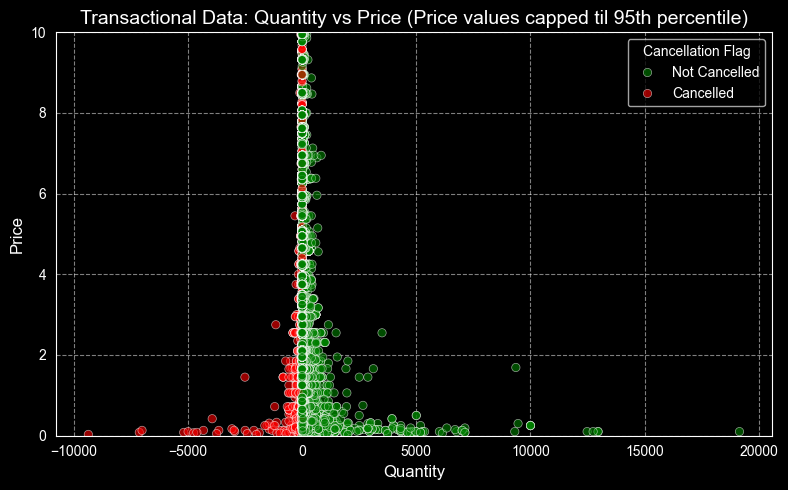

In [151]:
plt.figure(figsize=(8, 5))
scatter = sns.scatterplot(data=df, x='Quantity', y='Price', hue='Cancellation_flag', alpha=0.6, palette={0: 'g', 1: 'r'})

plt.title('Transactional Data: Quantity vs Price (Price values capped til 95th percentile)', fontsize=14)
plt.xlabel('Quantity', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.ylim(top=10, bottom=0)

handles, _ = scatter.get_legend_handles_labels()
plt.legend(handles=handles, title='Cancellation Flag', labels=['Not Cancelled', 'Cancelled'])

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

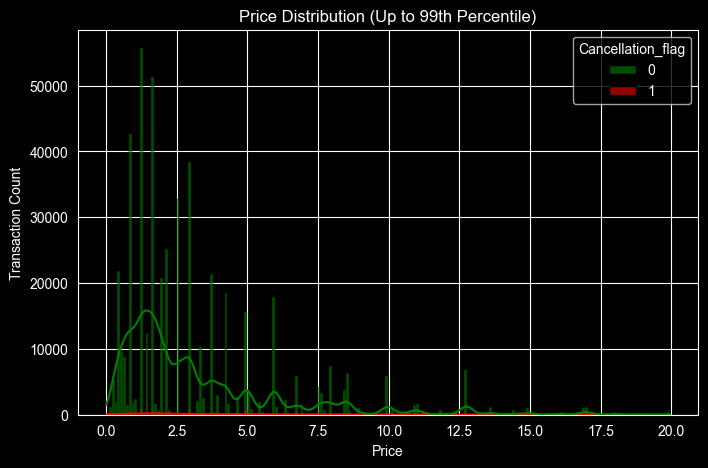

In [152]:
price_limit = df['Price'].quantile(0.99)

plt.figure(figsize=(8, 5))

sns.histplot(data=df[df['Price'] <= price_limit],x='Price',hue='Cancellation_flag', bins=200,kde=True,multiple='layer',alpha=0.6, edgecolor='black', palette={0: 'g', 1: 'r'})
plt.title('Price Distribution (Up to 99th Percentile)')
plt.xlabel('Price')
plt.ylabel('Transaction Count')
plt.show()

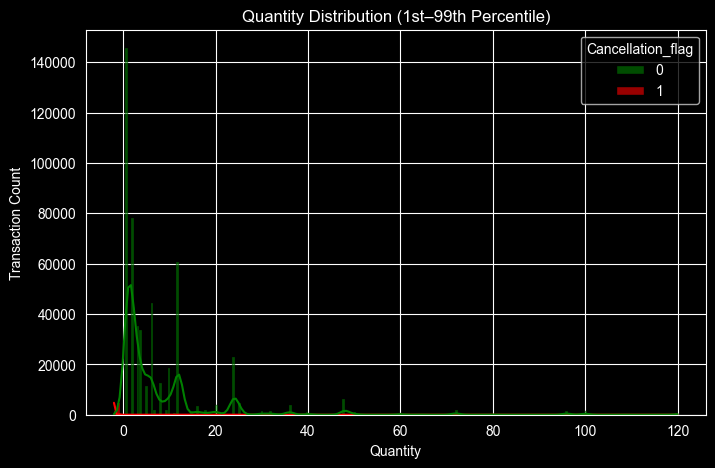

In [153]:
quantity_min = df['Quantity'].quantile(0.01)
quantity_max = df['Quantity'].quantile(0.99)

df_quantity_plot = df[df['Quantity'].between(quantity_min, quantity_max)]

plt.figure(figsize=(8, 5))
sns.histplot(data=df_quantity_plot,x='Quantity',hue='Cancellation_flag', palette={0: 'g', 1: 'r'}, bins=200,kde=True,multiple='layer',alpha=0.6, edgecolor='black')

plt.title('Quantity Distribution (1st–99th Percentile)')
plt.xlabel('Quantity')
plt.ylabel('Transaction Count')
plt.show()

In [154]:
df['OrderNetValue'] = np.where(df['Cancellation_flag'] == 0, df['Price'] * df['Quantity'], 0)

df["Transaction_Value"] = df["Quantity"] * df["Price"]

# To remove negative values
df["PurchasedQuantity"] = df["Quantity"].clip(lower=0)

# Keeps only negative values
df["CancelledQuantity"] = df["Quantity"].clip(upper=0).abs()

# Feature engineering

## Recency-Frequency-Monetary features (RFM)

In [155]:
first_period_date = df['InvoiceDate'].min()
last_period_date = df['InvoiceDate'].max()
date_delta = df['InvoiceDate'].max() -df['InvoiceDate'].min()
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

print(f'The earliest invoice date is {first_period_date}')
print(f'The latest invoice date is {last_period_date}')
print(f'The total time the dataset spans over is {date_delta}')
print(f'The snapshot date is {snapshot_date}')

The earliest invoice date is 2009-12-01 07:45:00
The latest invoice date is 2010-12-09 20:01:00
The total time the dataset spans over is 373 days 12:16:00
The snapshot date is 2010-12-10 20:01:00


### RFM fields

In [156]:
rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique',
    'OrderNetValue': 'sum'
})

rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'Invoice': 'Frequency',
    'OrderNetValue': 'Monetary'
}, inplace=True)

In [157]:
pd.set_option('display.float_format', '{:,.2f}'.format)

rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,"4,382.00","4,382.00","4,382.00"
mean,91.28,5.83,"2,351.87"
std,98.09,31.16,"23,930.14"
min,1.00,1.00,0.00
25%,17.00,1.00,298.45
50%,52.00,3.00,680.74
75%,138.00,6.00,"1,698.76"
max,374.00,"1,958.00","1,473,888.75"


#### RFM Distributions (Pre Transforming)

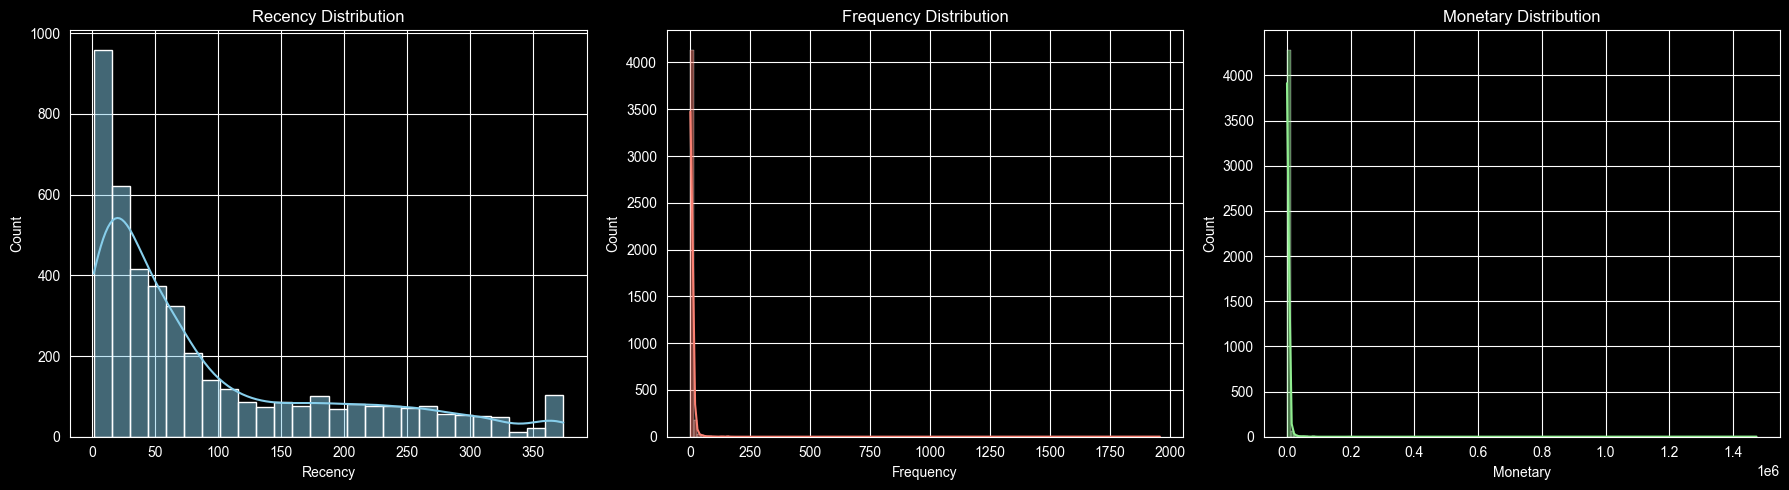

In [158]:
# Distributions of RFM features
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], kde=True, color='skyblue')
plt.title('Recency Distribution')

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], kde=True, color='salmon')
plt.title('Frequency Distribution')

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], kde=True, color='lightgreen')
plt.title('Monetary Distribution')

plt.tight_layout()
plt.show()

## Behavioral features

In [159]:
customer_behavior = df.groupby('Customer ID').agg({
    'PurchasedQuantity': 'sum',
    'CancelledQuantity': 'sum',
    'InvoiceDate': [lambda x: (x.max() - x.min()).days]
})
customer_behavior.columns = ['PurchasedQty', 'CancelledQty', 'Tenure']

In [160]:
rfm_extended = rfm.join(customer_behavior)

In [161]:
# Cancellation ratio per customer
rfm_extended['Cancellation_Rate'] = rfm_extended['CancelledQty'] / (rfm_extended['PurchasedQty'] + rfm_extended['CancelledQty']).replace(0, 1)

# Average Order Value per customer
rfm_extended['AOV'] = rfm_extended['Monetary'] / rfm_extended['Frequency']

In [162]:
rfm_extended.drop(columns=['PurchasedQty', 'CancelledQty'], inplace=True)

In [163]:
rfm_extended.columns

Index(['Recency', 'Frequency', 'Monetary', 'Tenure', 'Cancellation_Rate',
       'AOV'],
      dtype='str')

## Log Transform & Scale

### Log Transform

In [164]:
features_to_use = ['Recency', 'Frequency', 'Monetary', 'Tenure','Cancellation_Rate', 'AOV']

rfm_log = rfm_extended[features_to_use].apply(np.log1p, axis=1)

#### Distributions (Post Transforming)

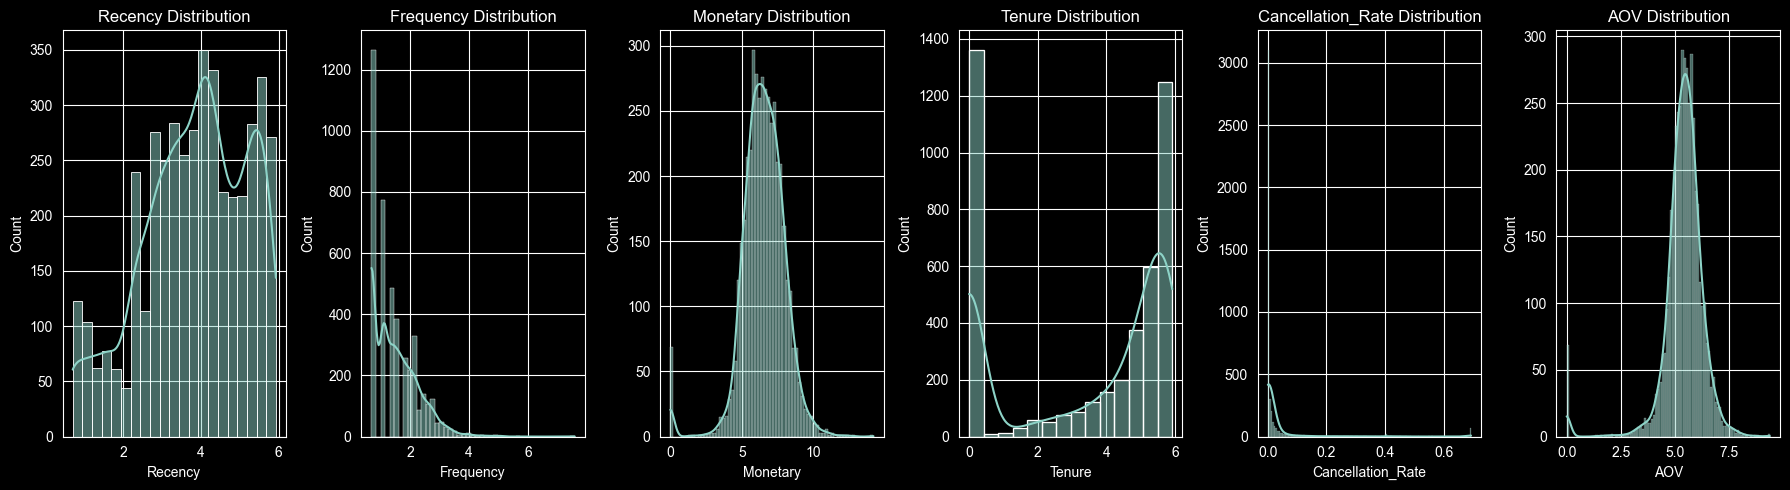

In [165]:
n_features = len(features_to_use)
plt.figure(figsize=(18, 5))

for i, feature in enumerate(features_to_use):
    plt.subplot(1, n_features, i + 1)
    sns.histplot(rfm_log[feature], kde=True)
    plt.title(f'{feature} Distribution')

plt.tight_layout()
plt.show()

### Checking For Multi-Collinearity

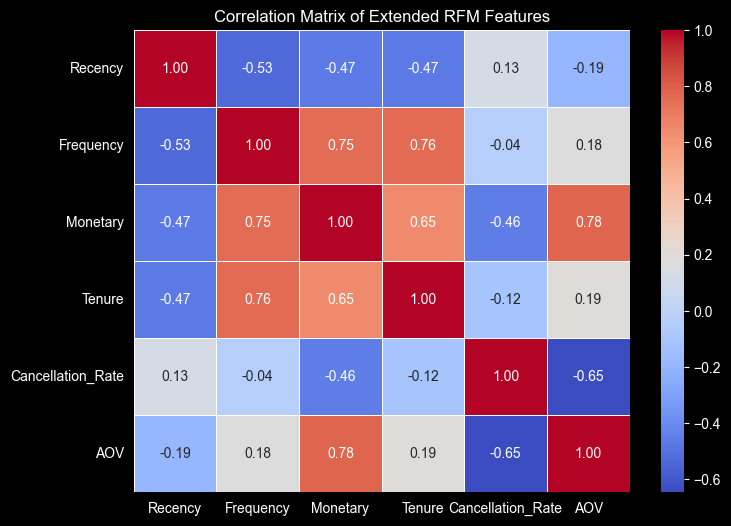

VIF Results:
             feature      VIF
2           Monetary 3,459.42
5                AOV 1,933.66
1          Frequency   274.88
0            Recency    11.53
3             Tenure    10.50
4  Cancellation_Rate     1.66


In [166]:
# Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(rfm_log.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Extended RFM Features')
plt.show()

# Variance Inflation Factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i) for i in range(len(df.columns))]
    return vif_data

vif_results = calculate_vif(rfm_log)
print("VIF Results:")
print(vif_results.sort_values(by="VIF", ascending=False))


There is an issue that both Frequency and Monetary fields are heavily correalated, therefore in order to reduce the impact of multicollinearity, Frequency was dropped. Dropping one is necessary to prevent the model from being biased toward the "volume/value" dimension.

In [167]:
rfm_log.drop(columns=['Frequency', 'AOV'], inplace=True)

### Scaling

In [168]:
scaler = RobustScaler()
X_scaled = scaler.fit_transform(rfm_log)

# K-Means Clustering

## Determining Optimal Number of Clusters

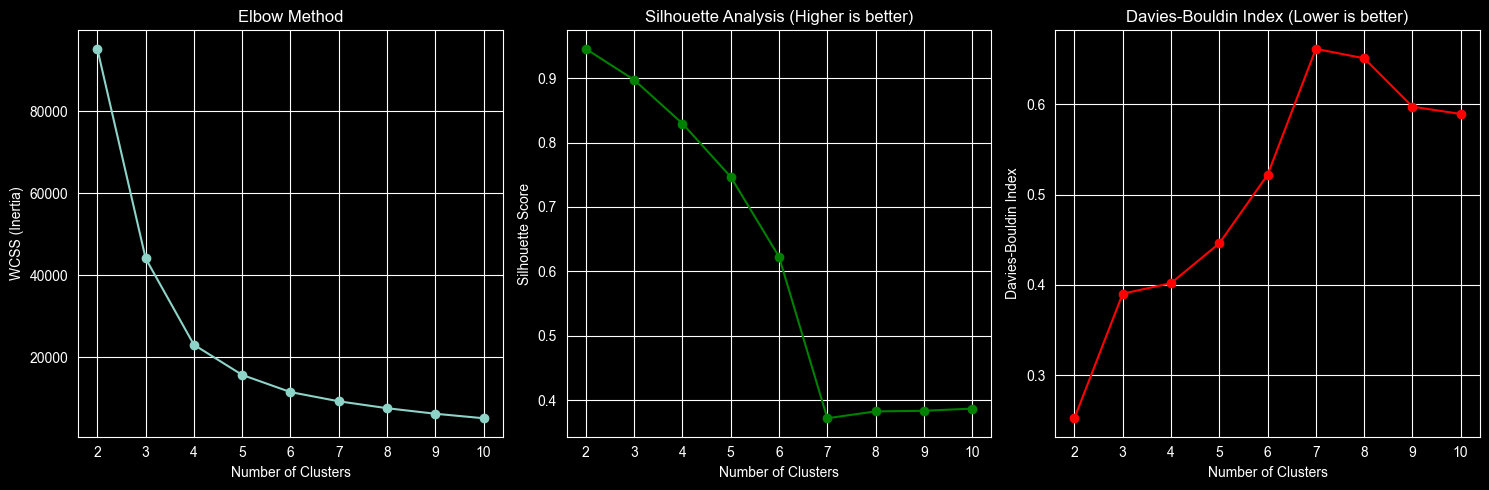

In [169]:
wcss = []
silhouette_scores = []
davies_bouldin_scores = []

from sklearn.metrics import silhouette_score, davies_bouldin_score

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )
    clusters = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, clusters))
    davies_bouldin_scores.append(davies_bouldin_score(X_scaled, clusters))

# Plot Elbow Method (WCSS)
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(range(2, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")

# Plot Silhouette Score
plt.subplot(1, 3, 2)
plt.plot(range(2, 11), silhouette_scores, marker="o", color='green')
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis (Higher is better)")

# Plot Davies-Bouldin Index
plt.subplot(1, 3, 3)
plt.plot(range(2, 11), davies_bouldin_scores, marker="o", color='red')
plt.xlabel("Number of Clusters")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index (Lower is better)")

plt.tight_layout()
plt.show()

In [170]:
# 4 cluster seem most optimal and making sense from business perspective
k = 4

kmeans = KMeans(
    n_clusters=k,
    init="k-means++",
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

In [171]:
rfm_extended["Cluster"] = clusters

## Visualize Clusters using PCA

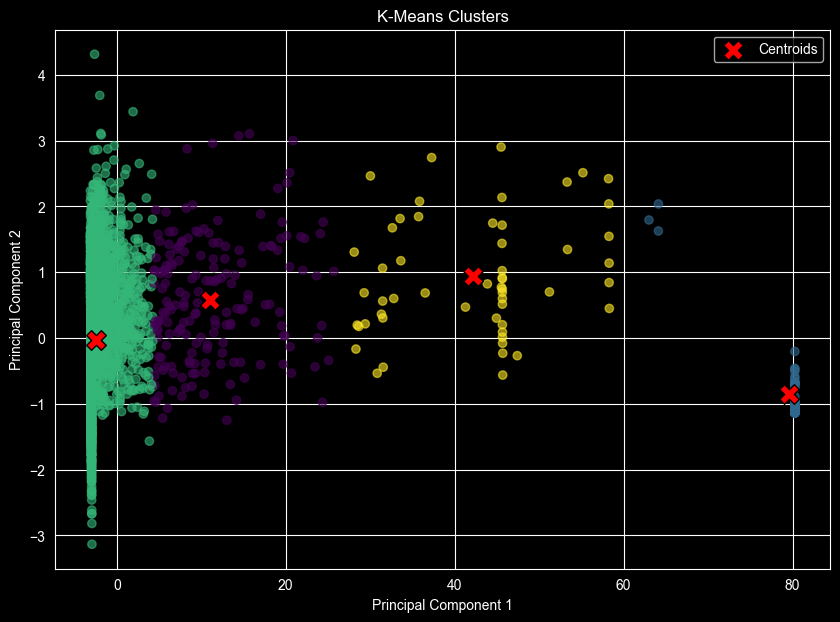

In [172]:
pca = PCA(n_components=4)

X_pca = pca.fit_transform(X_scaled)

# Transform cluster centers into PCA space
centers_pca = pca.transform(kmeans.cluster_centers_)

# Plot observations
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.6
)

# Plot centroids
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=200,
    c="red",
    edgecolor="black",
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters")
plt.legend()

plt.show()

In [173]:
# Calculate average values for each cluster
cluster_profile = rfm_extended.groupby('Cluster').agg({
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median'],
    'Tenure': ['mean', 'median'],
    'Cancellation_Rate': ['mean'],
    'AOV': ['mean', 'median']
}).round(2)

print(cluster_profile)

        Recency        Frequency        Monetary        Tenure         \
           mean median      mean median     mean median   mean median   
Cluster                                                                 
0         89.79  45.00      8.08   5.00 3,012.46 810.76 176.26 179.00   
1        244.24 262.00      1.26   1.00    50.01   0.00   6.97   0.00   
2         88.27  50.00      5.83   3.00 2,372.87 706.02 138.45 114.00   
3        119.19  90.00      4.17   3.00 1,633.81 318.30  70.46  13.00   

        Cancellation_Rate    AOV         
                     mean   mean median  
Cluster                                  
0                    0.13 269.81 160.57  
1                    0.99  11.42   0.00  
2                    0.01 322.30 244.12  
3                    0.46 315.04 104.94  


In [174]:
sil_score = silhouette_score(X_scaled, clusters)

print(f"Silhouette Score: {sil_score:.3f}")

# Cluster sizes
print(rfm_extended["Cluster"].value_counts())

# Cluster centers (scaled)
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=rfm_log.columns
)

print(centers)

Silhouette Score: 0.830
Cluster
2    4076
0     180
1      72
3      54
Name: count, dtype: int64
   Recency  Monetary  Tenure  Cancellation_Rate
0    -0.12      0.17   -0.06              14.16
1     0.65     -3.59   -0.79              82.57
2    -0.08      0.05   -0.23               0.60
3     0.15     -0.29   -0.38              45.19


In [175]:
print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())

[9.91433606e-01 6.10230241e-03 1.84945315e-03 6.14638200e-04]
0.9999999999999999


# DBSCAN Clustering
DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is useful for finding clusters of arbitrary shape and identifying outliers (noise).

### 1. Finding Optimal eps (K-Distance Graph)
We use the `NearestNeighbors` to find the distance to the *k-th* nearest neighbor. The "elbow" in this plot suggests a good value for `eps`.

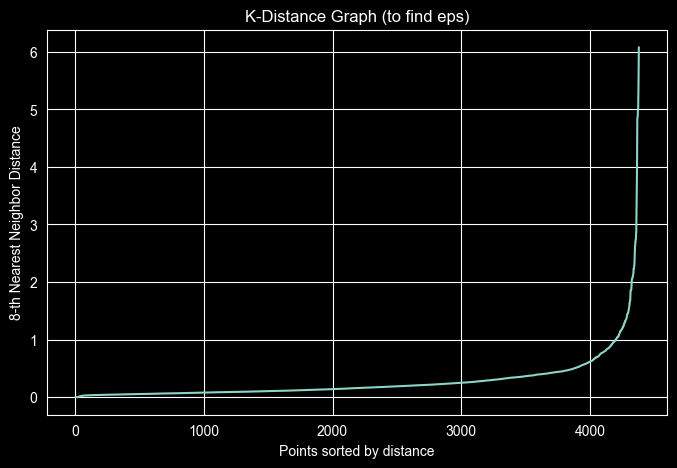

In [176]:
from sklearn.neighbors import NearestNeighbors

min_samples = 2 * X_scaled.shape[1]

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, min_samples-1], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title("K-Distance Graph (to find eps)")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples}-th Nearest Neighbor Distance")
plt.grid(True)
plt.show()

### 2. Fit DBSCAN

In [177]:
from sklearn.cluster import DBSCAN

eps_value = 0.5

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
dbscan_clusters = dbscan.fit_predict(X_scaled)

rfm_extended['DBSCAN_Cluster'] = dbscan_clusters

print(f"Number of clusters found: {len(set(dbscan_clusters)) - (1 if -1 in dbscan_clusters else 0)}")
print(f"Number of noise points: {list(dbscan_clusters).count(-1)}")

Number of clusters found: 3
Number of noise points: 387


### 3. Visualize DBSCAN Clusters (PCA)

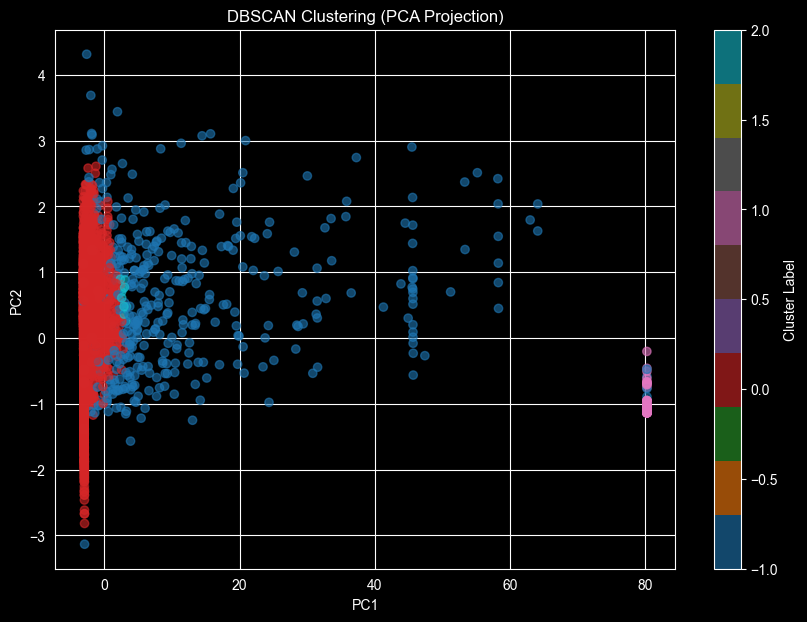

In [178]:
plt.figure(figsize=(10, 7))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_clusters,
    cmap="tab10", # Using tab10 to better distinguish noise (-1)
    alpha=0.6
)
plt.title("DBSCAN Clustering (PCA Projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label='Cluster Label')
plt.show()

### 4. Profile DBSCAN Clusters

In [179]:
dbscan_profile = rfm_extended.groupby('DBSCAN_Cluster').agg({
    'Recency': ['mean', 'count'],
    'Frequency': ['mean'],
    'Monetary': ['mean'],
    'Tenure': ['mean'],
    'Cancellation_Rate': ['mean']
}).round(2)

print(dbscan_profile)


               Recency       Frequency  Monetary Tenure Cancellation_Rate
                  mean count      mean      mean   mean              mean
DBSCAN_Cluster                                                           
-1               95.53   387     16.70 10,734.87 153.10              0.15
 0               88.45  3920      4.83  1,567.09 137.53              0.00
 1              248.72    65      1.03      0.00   0.00              1.00
 2               12.10    10      6.40    850.24 200.60              0.05


# K-Medoids clustering
K-Medoids is similar to K-Means but uses actual data points (medoids) as cluster centers, making it more robust to noise and outliers.

In [180]:
k_medoids = 4

kmedoids = KMedoids(n_clusters=k_medoids, random_state=42, init='k-medoids++')
kmedoids_clusters = kmedoids.fit_predict(X_scaled)

rfm_extended['KMedoids_Cluster'] = kmedoids_clusters

/opt/anaconda3/envs/PyCharmMiscProject/lib/python3.13/site-packages/sklearn/utils/deprecation.py:95: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


### Visualize K-Medoids Clusters (PCA)

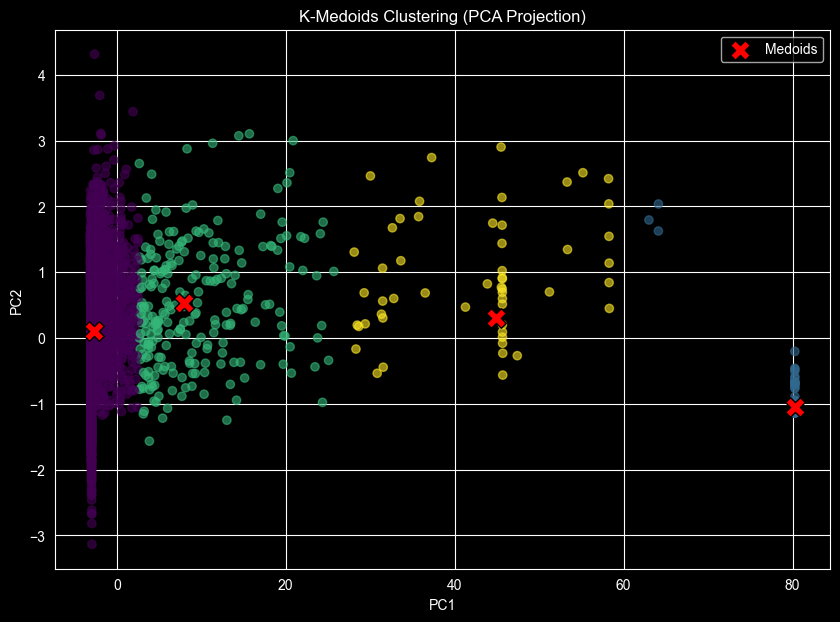

In [181]:
plt.figure(figsize=(10, 7))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmedoids_clusters,
    cmap="viridis",
    alpha=0.6
)

# Plot medoids
medoids_pca = pca.transform(kmedoids.cluster_centers_)
plt.scatter(
    medoids_pca[:, 0],
    medoids_pca[:, 1],
    marker="X",
    s=200,
    c="red",
    edgecolor="black",
    label="Medoids"
)

plt.title("K-Medoids Clustering (PCA Projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

### Profile K-Medoids Clusters

In [182]:
kmedoids_profile = rfm_extended.groupby('KMedoids_Cluster').agg({
    'Recency': ['mean', 'median', 'count'],
    'Frequency': ['mean'],
    'Monetary': ['mean'],
    'Tenure': ['mean'],
    'Cancellation_Rate': ['mean']
}).round(2)

print(kmedoids_profile)


                 Recency              Frequency Monetary Tenure  \
                    mean median count      mean     mean   mean   
KMedoids_Cluster                                                  
0                  88.20  50.00  4017      5.81 2,364.81 138.21   
1                 244.24 262.00    72      1.26    50.01   6.97   
2                  90.67  46.00   239      7.84 2,990.12 171.00   
3                 119.19  90.00    54      4.17 1,633.81  70.46   

                 Cancellation_Rate  
                              mean  
KMedoids_Cluster                    
0                             0.00  
1                             0.99  
2                             0.11  
3                             0.46  


# HDBSCAN
HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise) is an extension of DBSCAN that finds clusters of varying densities and is more robust to parameter selection.

In [183]:
from sklearn.cluster import HDBSCAN

# HDBSCAN typically requires min_cluster_size
hdbscan = HDBSCAN(min_cluster_size=15, min_samples=5)
hdbscan_clusters = hdbscan.fit_predict(X_scaled)

rfm_extended['HDBSCAN_Cluster'] = hdbscan_clusters

print(f"Number of clusters found: {len(set(hdbscan_clusters)) - (1 if -1 in hdbscan_clusters else 0)}")
print(f"Number of noise points: {list(hdbscan_clusters).count(-1)}")

Number of clusters found: 14
Number of noise points: 1944


/opt/anaconda3/envs/PyCharmMiscProject/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


### Visualize HDBSCAN Clusters (PCA)

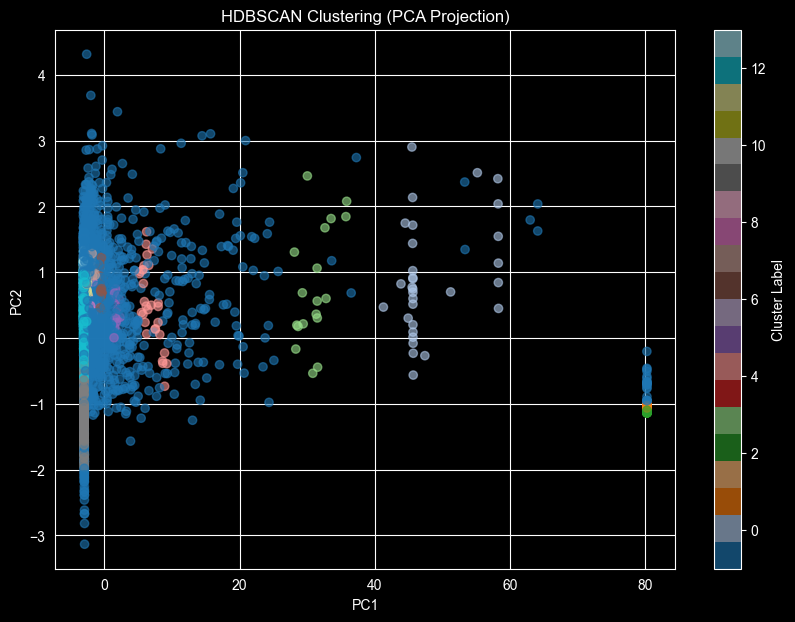

In [184]:
plt.figure(figsize=(10, 7))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hdbscan_clusters,
    cmap="tab20",
    alpha=0.6
)
plt.title("HDBSCAN Clustering (PCA Projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label='Cluster Label')
plt.show()

### Profile HDBSCAN Clusters

In [185]:
hdbscan_profile = rfm_extended.groupby('HDBSCAN_Cluster').agg({
    'Recency': ['mean', 'median', 'count'],
    'Frequency': ['mean'],
    'Monetary': ['mean'],
    'Tenure': ['mean'],
    'Cancellation_Rate': ['mean']
}).round(2)

print(hdbscan_profile)


                Recency              Frequency Monetary Tenure  \
                   mean median count      mean     mean   mean   
HDBSCAN_Cluster                                                  
-1                64.31  29.00  1944      9.40 4,207.39 172.42   
 0               124.26  81.00    31      3.42 1,284.02  33.87   
 1               252.32 260.00    19      1.05     0.00   0.00   
 2               346.18 364.00    28      1.04     0.00   0.00   
 3               108.11  94.00    18      5.17 1,095.03 121.28   
 4                63.80  31.00    30      7.57 1,291.20 201.03   
 5                78.67  71.00    15      8.13 1,613.71 233.47   
 6                35.81  31.00    27      9.37 2,225.02 275.67   
 7                18.52  15.00    25      9.92 2,644.21 302.80   
 8                58.49  59.00    35      8.00 2,482.06 260.03   
 9               162.71 149.50  1066      1.04   279.41   0.00   
 10               10.29  11.00    17      1.06   313.44   0.00   
 11       

# GMM Clustering
Gaussian Mixture Models (GMM) assume that the data is generated from a mixture of several Gaussian distributions. Unlike K-Means, it provides "soft" assignments (probabilities) and can handle clusters with different shapes (ellipsoidal).

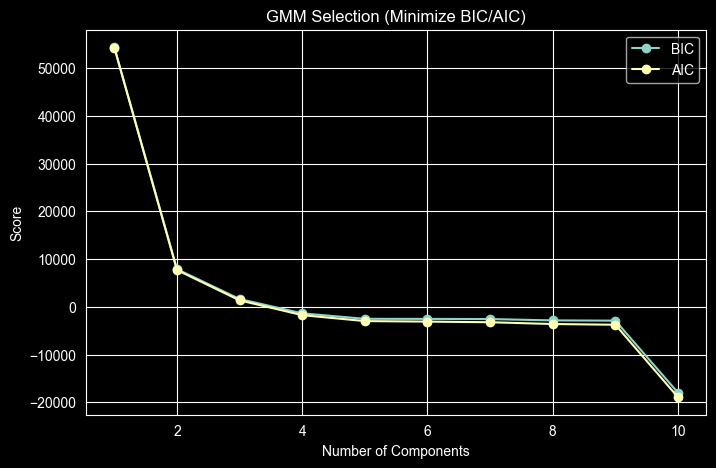

In [186]:
from sklearn.mixture import GaussianMixture

n_components_range = range(1, 11)
bics = []
aics = []

for n in n_components_range:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(X_scaled)
    bics.append(gmm.bic(X_scaled))
    aics.append(gmm.aic(X_scaled))

plt.figure(figsize=(8, 5))
plt.plot(n_components_range, bics, label='BIC', marker='o')
plt.plot(n_components_range, aics, label='AIC', marker='o')
plt.legend()
plt.xlabel('Number of Components')
plt.ylabel('Score')
plt.title('GMM Selection (Minimize BIC/AIC)')
plt.show()

In [187]:
# Fit GMM with chosen number of components
k_gmm = 4
gmm = GaussianMixture(n_components=k_gmm, random_state=42)
gmm_clusters = gmm.fit_predict(X_scaled)

rfm_extended['GMM_Cluster'] = gmm_clusters

# GMM also provides probabilities for each cluster
probs = gmm.predict_proba(X_scaled)
print(f"Probabilities shape: {probs.shape}")

Probabilities shape: (4382, 4)


### Visualize GMM Clusters (PCA)

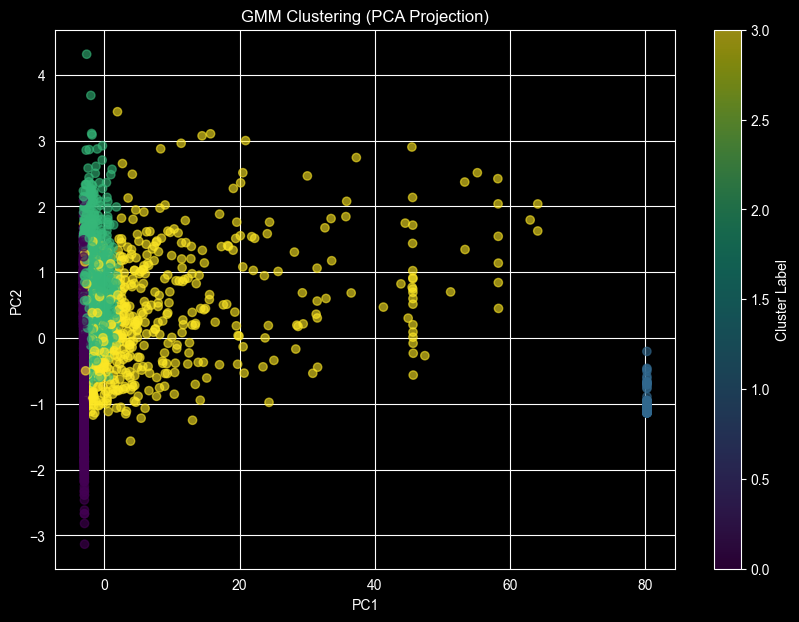

In [188]:
plt.figure(figsize=(10, 7))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=gmm_clusters,
    cmap="viridis",
    alpha=0.6
)

plt.title("GMM Clustering (PCA Projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label='Cluster Label')
plt.show()

### Profile GMM Clusters

In [190]:
gmm_profile = rfm_extended.groupby('GMM_Cluster').agg({
    'Recency': ['mean', 'median', 'count'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median'],
    'Tenure': ['mean', 'median'],
    'Cancellation_Rate': ['mean']
}).round(2)

print(gmm_profile)


            Recency              Frequency        Monetary          Tenure  \
               mean median count      mean median     mean   median   mean   
GMM_Cluster                                                                  
0            107.96  65.00  2583      2.41   2.00   824.34   432.18  88.87   
1            246.00 262.00    69      1.09   1.00     0.00     0.00   3.57   
2             42.86  24.00  1101     14.02   8.00 6,189.82 2,276.49 277.71   
3             90.56  49.00   629      6.06   4.00 2,164.74   717.62 103.01   

                   Cancellation_Rate  
            median              mean  
GMM_Cluster                           
0             9.00              0.00  
1             0.00              1.00  
2           292.00              0.01  
3            56.00              0.09  


In [192]:
rfm_extended.head(3)

,Recency,Frequency,Monetary,Tenure,Cancellation_Rate,AOV,Cluster,DBSCAN_Cluster,KMedoids_Cluster,HDBSCAN_Cluster,GMM_Cluster
Customer ID,,,,,,,,,,,
0.00,1,1958,"1,473,888.75",373,0.00,752.75,2,-1,0,-1,2
"12,346.00",67,15,372.86,294,0.20,24.86,0,-1,2,-1,3
"12,347.00",3,2,"1,323.32",37,0.00,661.66,2,0,0,-1,0


# Results and Conclusions

### Clustering Method Selection
K-Medoids and Gaussian Mixture Models (GMM) appeared to be the most suitable clustering methods for this dataset, providing meaningful and interpretable customer segments. In contrast, DBSCAN and HDBSCAN produced overly granular segmentations that could be difficult to interpret and translate into actionable business strategies.
Based on the clustering evaluation metrics and the interpretability of the resulting segments, 4 clusters were selected as the optimal segmentation.

### Customer Segment Profiles
Based on GMM clusters, following cluster description was made:

#### Cluster 0 — Occasional Customers
The largest customer segment, consisting of customers with relatively low purchase frequency and monetary contribution. Their purchasing activity is comparatively limited, suggesting that they may represent occasional shoppers with potential for increased engagement and repeat purchases.
#### Cluster 1 — Cancelled Customers
A small segment of customers whose orders were cancelled, resulting in no completed monetary contribution. These customers exhibit low purchasing activity and the longest time since their last recorded transaction. Understanding the reasons behind these cancellations could help identify potential issues in the purchasing process.
#### Cluster 2 — High-Value Loyal Customers
The most valuable customer segment, characterized by the highest purchase frequency and monetary contribution, alongside the lowest recency. These customers demonstrate strong purchasing engagement and consistently low cancellation rates, making them particularly important to the business. Retaining these customers and maintaining their positive purchasing experience should be a priority.
#### Cluster 3 — Regular High-Value Customers
The second-most valuable customer segment, characterized by relatively frequent purchases and substantial monetary contribution. Although these customers exhibit lower purchasing activity and monetary value than Cluster 2, their metrics indicate an established level of engagement. They may represent an opportunity for further growth through targeted retention and customer development strategies.

### Key Takeaway
The segmentation reveals four distinct customer groups with different purchasing behaviors and potential business implications. While High-Value Loyal Customers represent the most valuable segment to retain, Regular High-Value Customers offer opportunities to increase customer value further. Occasional Customers could be targeted with initiatives to encourage repeat purchases, while Cancelled Customers warrant further investigation to understand the reasons behind their cancelled orders.